# Experiment 4: Principal Component Analysis on Smartphone Dataset

**Aim:** To implement Principal Component Analysis (PCA) on a Smartphone Dataset using Python and reduce the dimensionality of the dataset while preserving maximum variance present in the original data.

**Dataset:** `datasets/smartphone_cleaned_data.csv` - 980 smartphones with price, rating, display, camera, RAM, storage, battery and processor attributes.

In [1]:
# Principal Component Analysis on Smartphone Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Display plots inside Jupyter Notebook
%matplotlib inline

# Set plotting style
sns.set(style="whitegrid")
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Load Dataset
df = pd.read_csv("datasets/smartphone_cleaned_data.csv")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (980, 22)
  brand_name                    model   price  avg_rating  5G_or_not  \
0      apple          Apple iPhone 11   38999         7.3          0   
1      apple  Apple iPhone 11 (128GB)   46999         7.5          0   
2      apple  Apple iPhone 11 Pro Max  109900         7.7          0   
3      apple          Apple iPhone 12   51999         7.4          1   
4      apple  Apple iPhone 12 (128GB)   55999         7.5          1   

  processor_brand  num_cores  processor_speed  battery_capacity  \
0          bionic        6.0             2.65            3110.0   
1          bionic        6.0             2.65            3110.0   
2          bionic        6.0             2.65            3500.0   
3          bionic        6.0             3.10               NaN   
4          bionic        6.0             3.10               NaN   

   fast_charging_available  ...  internal_memory  screen_size  refresh_rate  \
0                        0  ...               64          6.

In [3]:
# Basic dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 980 entries, 0 to 979
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 980 non-null    object 
 1   model                      980 non-null    object 
 2   price                      980 non-null    int64  
 3   avg_rating                 879 non-null    float64
 4   5G_or_not                  980 non-null    int64  
 5   processor_brand            960 non-null    object 
 6   num_cores                  974 non-null    float64
 7   processor_speed            938 non-null    float64
 8   battery_capacity           969 non-null    float64
 9   fast_charging_available    980 non-null    int64  
 10  fast_charging              769 non-null    float64
 11  ram_capacity               980 non-null    int64  
 12  internal_memory            980 non-null    int64  
 13  screen_size                980 non-null    float64

In [4]:
# Statistical summary
print(df.describe().T)

                           count          mean           std      min  \
price                      980.0  32520.504082  39531.812669  3499.00   
avg_rating                 879.0      7.825825      0.740285     6.00   
5G_or_not                  980.0      0.560204      0.496616     0.00   
num_cores                  974.0      7.772074      0.836845     4.00   
processor_speed            938.0      2.427217      0.464090     1.20   
battery_capacity           969.0   4817.748194   1009.540054  1821.00   
fast_charging_available    980.0      0.854082      0.353205     0.00   
fast_charging              769.0     46.126138     34.277870    10.00   
ram_capacity               980.0      6.560204      2.744378     1.00   
internal_memory            980.0    141.036735    107.134516     8.00   
screen_size                980.0      6.536765      0.349162     3.54   
refresh_rate               980.0     92.256122     28.988052    60.00   
num_rear_cameras           980.0      2.814286     

In [5]:
# Missing values and duplicate records
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate records:", df.duplicated().sum())

Missing values per column:
brand_name                     0
model                          0
price                          0
avg_rating                   101
5G_or_not                      0
processor_brand               20
num_cores                      6
processor_speed               42
battery_capacity              11
fast_charging_available        0
fast_charging                211
ram_capacity                   0
internal_memory                0
screen_size                    0
refresh_rate                   0
num_rear_cameras               0
os                            14
primary_camera_rear            0
primary_camera_front           5
extended_memory_available      0
resolution_height              0
resolution_width               0
dtype: int64

Duplicate records: 0


Numerical features: ['price', 'avg_rating', '5G_or_not', 'num_cores', 'processor_speed', 'battery_capacity', 'fast_charging_available', 'fast_charging', 'ram_capacity', 'internal_memory', 'screen_size', 'refresh_rate', 'num_rear_cameras', 'primary_camera_rear', 'primary_camera_front', 'extended_memory_available', 'resolution_height', 'resolution_width']


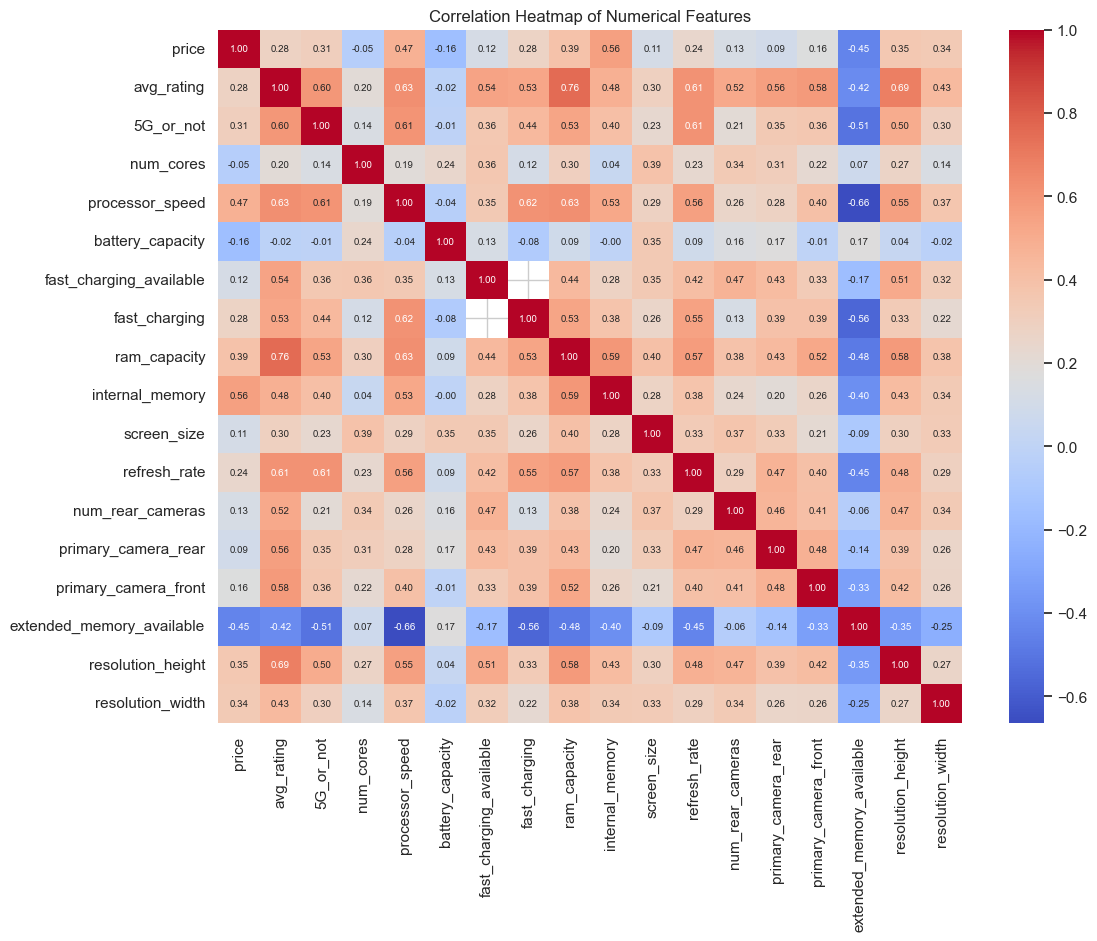

In [6]:
# Select Numerical Features
numeric_df = df.select_dtypes(include=np.number).copy()
print("Numerical features:", list(numeric_df.columns))

# Correlation among numerical features
plt.figure(figsize=(12, 9))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation Heatmap of Numerical Features")
plt.savefig("output/Exp4_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Handle Missing Values (median imputation)
for column in numeric_df.columns:
    numeric_df[column] = numeric_df[column].fillna(
        numeric_df[column].median()
    )
print("Missing values after imputation:", numeric_df.isnull().sum().sum())

# Standardize Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(numeric_df)

print("Shape of Standardized Data:")
print(X_scaled.shape)

Missing values after imputation: 0
Shape of Standardized Data:
(980, 18)


In [8]:
# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("PCA Shape:", X_pca.shape)

# Explained Variance Ratio
print("\nExplained Variance Ratio")
for i, variance in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"PC{i}: {variance*100:.2f}%")

# Cumulative Explained Variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

print("\nCumulative Explained Variance")
for i, variance in enumerate(cumulative_variance, start=1):
    print(f"PC1 to PC{i}: {variance*100:.2f}%")

Original Shape: (980, 18)
PCA Shape: (980, 18)

Explained Variance Ratio
PC1: 38.19%
PC2: 11.90%
PC3: 6.81%
PC4: 5.98%
PC5: 4.61%
PC6: 4.26%
PC7: 3.97%
PC8: 3.15%
PC9: 2.86%
PC10: 2.82%
PC11: 2.68%
PC12: 2.55%
PC13: 2.14%
PC14: 1.96%
PC15: 1.79%
PC16: 1.60%
PC17: 1.54%
PC18: 1.20%

Cumulative Explained Variance
PC1 to PC1: 38.19%
PC1 to PC2: 50.09%
PC1 to PC3: 56.90%
PC1 to PC4: 62.88%
PC1 to PC5: 67.49%
PC1 to PC6: 71.74%
PC1 to PC7: 75.72%
PC1 to PC8: 78.87%
PC1 to PC9: 81.73%
PC1 to PC10: 84.55%
PC1 to PC11: 87.23%
PC1 to PC12: 89.77%
PC1 to PC13: 91.92%
PC1 to PC14: 93.88%
PC1 to PC15: 95.67%
PC1 to PC16: 97.27%
PC1 to PC17: 98.80%
PC1 to PC18: 100.00%


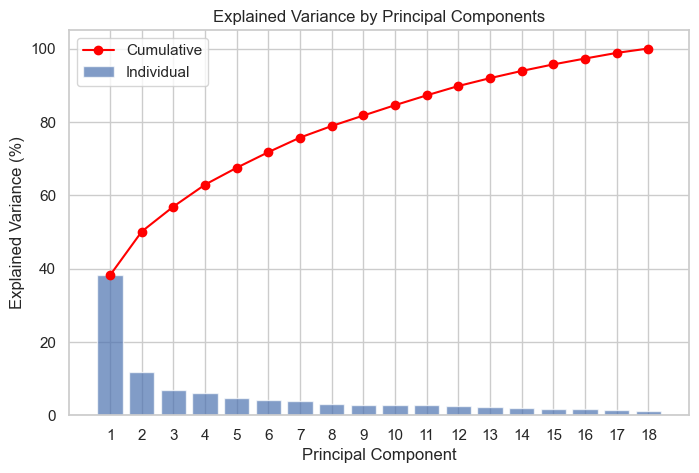

In [9]:
# Explained variance plot
components = np.arange(1, len(cumulative_variance) + 1)
plt.figure(figsize=(8, 5))
plt.bar(components, pca.explained_variance_ratio_ * 100, alpha=0.7, label="Individual")
plt.plot(components, cumulative_variance * 100, color="red", marker="o", label="Cumulative")
plt.xticks(components)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance by Principal Components")
plt.legend()
plt.savefig("output/Exp4_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Reduce Data to Two Principal Components
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

print("Total Variance Explained by First Two Components:")
print(np.sum(pca_2.explained_variance_ratio_) * 100)

# Create DataFrame of Principal Components
pca_df = pd.DataFrame(X_pca_2, columns=["PC1", "PC2"])

print("\nFirst Five Records")
print(pca_df.head())

Total Variance Explained by First Two Components:
50.08722320655949

First Five Records
        PC1       PC2
0 -3.017290 -3.478077
1 -2.755383 -3.660733
2 -0.732366 -2.298405
3 -1.391846 -3.259969
4 -1.190156 -3.405543


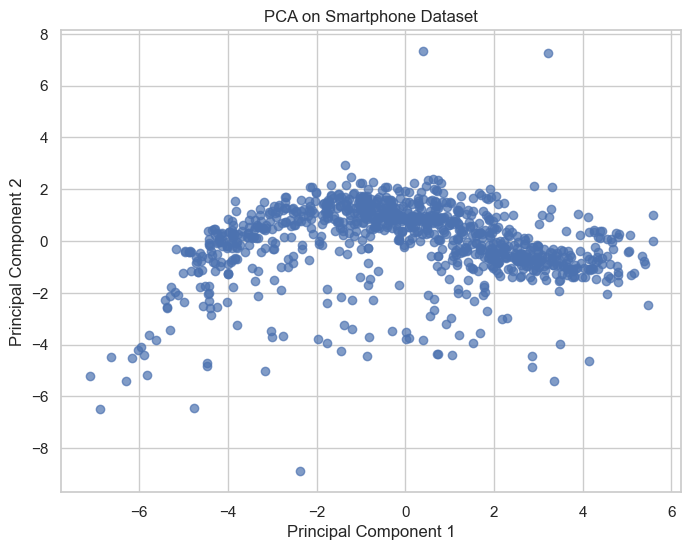

In [11]:
# Visualize PCA Components
plt.figure(figsize=(8, 6))
plt.scatter(pca_df["PC1"], pca_df["PC2"], alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Smartphone Dataset")
plt.grid(True)
plt.savefig("output/Exp4_pca_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
Principal Component Analysis was successfully implemented on the Smartphone Dataset. The numerical features were median-imputed, standardized and transformed into principal components, reducing dimensionality while preserving most of the variance. The data was visualized using the first two principal components.